# Kanter med Sobel

En kant er et sted der lysstyrken endrer seg brått. `cv2.Sobel` regner ut hvor fort lysstyrken endrer seg (den deriverte, eller *gradienten*) i hver piksel:

- **Sobel x** (`dx=1, dy=0`) måler endringen bortover. Den finner kanter som går **loddrett**.
- **Sobel y** (`dx=0, dy=1`) måler endringen nedover. Den finner kanter som går **vannrett**.
- Sammen gir de **styrken** på kanten, `√(gx² + gy²)`, og **retningen** den peker i.

Bildet `stjerne.png` i `bilder/` har 8 hvite streker gjennom midten, med 22,5° mellom hver: 0° (vannrett), 22,5°, 45° og så videre til 157,5°. Da ser du hvordan vinkelen på en strek påvirker hva Sobel finner.

Kjør cellene med **Shift+Enter**, eller trykk **Kjør alle**.

(400, 400) uint8 vinkler: [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]


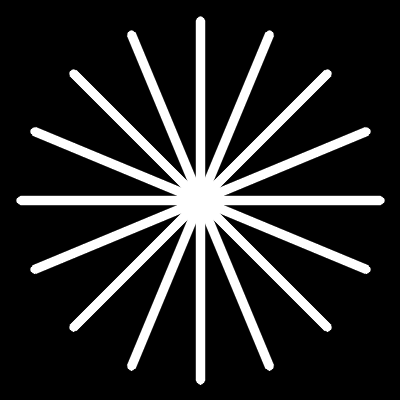

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact


def lag_stjerne(antall=8, tykkelse=7, storrelse=400):
    """Hvite streker gjennom midten på svart bakgrunn, med like store vinkler mellom.
    Gir bildet og vinklene til strekene i grader (0 = vannrett, økende mot klokka)."""
    bilde = np.zeros((storrelse, storrelse), np.uint8)
    c = storrelse // 2
    r = c - 20                                   # fra midten til enden av en strek
    vinkler = np.arange(antall) * 180 / antall
    for v in vinkler:
        a = np.radians(v)
        dx, dy = r * np.cos(a), r * np.sin(a)    # y peker nedover i bilder, derfor + og − for y
        cv2.line(bilde, (round(c - dx), round(c + dy)), (round(c + dx), round(c - dy)), 255, tykkelse, cv2.LINE_AA)
    return bilde, vinkler


img = cv2.imread("stjerne.png", cv2.IMREAD_GRAYSCALE)   # fra mappen bilder/, laget med lag_stjerne()
vinkler = np.arange(8) * 180 / 8                         # 0, 22.5, 45 … 157.5 grader
if img is None:                                          # finnes ikke bildet, lages det her
    img, vinkler = lag_stjerne()

# Vil du prøve flere vinkler eller tynnere streker, kan du lage en ny stjerne:
# img, vinkler = lag_stjerne(antall=12, tykkelse=3)

print(img.shape, img.dtype, "vinkler:", vinkler)
cv2.imshow("stjerne", img)

## Sobel x og Sobel y

`cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)` legger en 3 × 3-kjerne over hver piksel (kjernene skrives ut under). Kjernen for x trekker venstre side fra høyre side, så den gir

- **positive tall** (rødt under) der det blir lysere mot høyre
- **negative tall** (blått) der det blir mørkere mot høyre
- **0** (hvitt) der lysstyrken ikke endrer seg bortover

Resultatet lagres som flyttall (`cv2.CV_64F`). Med `cv2.CV_8U` blir alle negative tall 0, og da forsvinner halvparten av kantene.

Hver hvit strek har to kanter, én på hver side: den ene går fra mørkt til lyst, den andre fra lyst til mørkt. Derfor har hver strek en rød og en blå side. Se også hvordan den vannrette streken nesten forsvinner i Sobel x, og den loddrette i Sobel y.

Sobel x:
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
Sobel y:
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


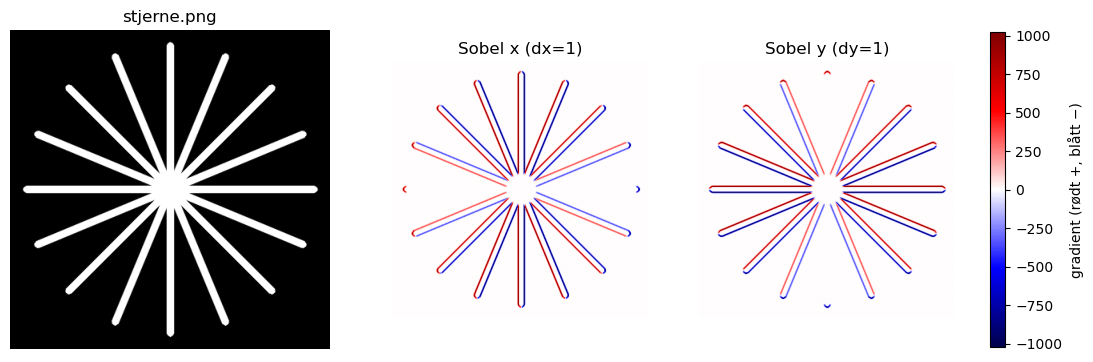

In [2]:
gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)   # endring bortover: finner loddrette kanter
gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)   # endring nedover: finner vannrette kanter

# Kjernene: utjevning (1, 2, 1) den ene veien og derivert (−1, 0, 1) den andre
for navn, dx, dy in [("x", 1, 0), ("y", 0, 1)]:
    kx, ky = cv2.getDerivKernels(dx, dy, 3)
    print(f"Sobel {navn}:")
    print((ky @ kx.T).astype(int))

grense = np.abs(np.concatenate([gx, gy])).max()   # samme skala for begge, med 0 i midten
fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("stjerne.png")
for a, g, tittel in [(ax[1], gx, "Sobel x (dx=1)"), (ax[2], gy, "Sobel y (dy=1)")]:
    vist = a.imshow(g, cmap="seismic", vmin=-grense, vmax=grense)
    a.set_title(tittel)
for a in ax:
    a.axis("off")
fig.colorbar(vist, ax=ax[1:], shrink=0.85, label="gradient (rødt +, blått −)")
plt.show()

## Styrke og retning

- **Styrken** `cv2.magnitude(gx, gy)` er `√(gx² + gy²)`. Den er stor på alle kantene, uansett vinkel.
- **Retningen** `cv2.phase(gx, gy, angleInDegrees=True)` er vinkelen gradienten peker i, fra mørkt mot lyst, fra 0 til 360 grader. Den står vinkelrett på streken. Siden y peker nedover i bilder, går vinkelen med klokka.

Under vises retningen som farge med HSV, slik du kjenner det fra Fargelab-fanen: **H** er retningen, **S** er 255 og **V** er styrken. Kanter som peker samme vei, får samme farge. De to sidene av en strek peker motsatt vei, så fargene deres ligger 180° fra hverandre på fargehjulet.

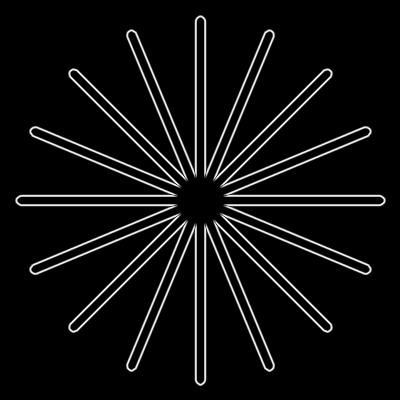

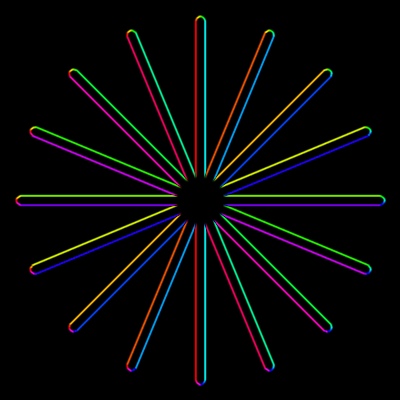

In [3]:
styrke = cv2.magnitude(gx, gy)                     # √(gx² + gy²)
retning = cv2.phase(gx, gy, angleInDegrees=True)   # 0–360 grader

styrke8 = cv2.normalize(styrke, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

hsv = np.zeros((*img.shape, 3), np.uint8)
hsv[..., 0] = (retning / 2).astype(np.uint8)       # H går fra 0 til 179 i OpenCV, så gradene deles på 2
hsv[..., 1] = 255
hsv[..., 2] = styrke8
retning_farge = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

cv2.imshow("styrke", styrke8)
cv2.imshow("retning som farge (H = retning, V = styrke)", retning_farge)

## Hvor godt blir hver strek funnet?

Her måles gjennomsnittet av |Sobel x|, |Sobel y| og styrken langs hver av strekene. Midten, der alle strekene møtes, er tatt bort. De stiplede linjene er teorien. For en strek med vinkel θ står kanten vinkelrett på streken, så

- **|Sobel x| ≈ styrke · |sin θ|:** størst for loddrette streker (90°), nesten 0 for vannrette (0°)
- **|Sobel y| ≈ styrke · |cos θ|:** størst for vannrette streker, nesten 0 for loddrette
- **styrken** er nesten lik for alle vinkler, fordi sin² θ + cos² θ = 1

Derfor trenger du både x og y for å finne kanter i alle retninger.

 vinkel   |Sobel x|  |Sobel y|   styrke
   0.0°        6.2      150.0     153.2
  22.5°       60.9      138.3     153.1
  45.0°      110.1      110.1     156.7
  67.5°      138.3       60.9     153.0
  90.0°      150.1        6.2     153.2
 112.5°      138.3       60.9     153.0
 135.0°      110.1      110.1     156.7
 157.5°       60.9      138.3     153.1


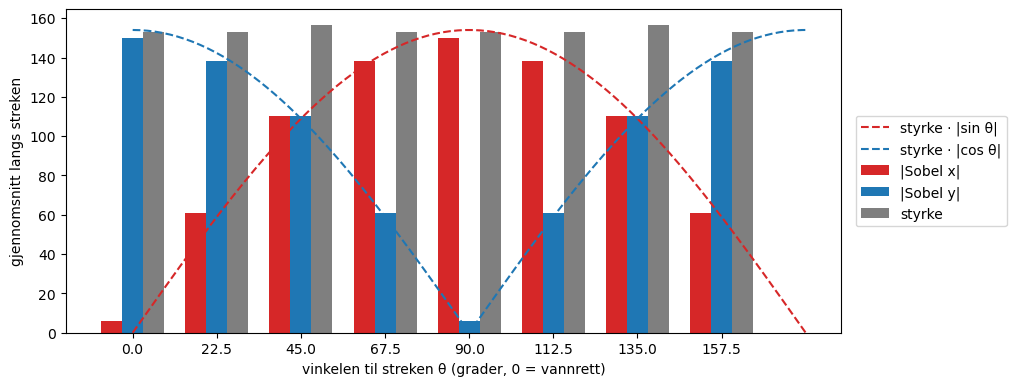

In [4]:
c = img.shape[0] // 2
r = c - 25
maaling = []
for v in vinkler:
    # En maske langs streken: en bred linje oppå streken, uten midten
    maske = np.zeros_like(img)
    a = np.radians(v)
    dx, dy = r * np.cos(a), r * np.sin(a)
    cv2.line(maske, (round(c - dx), round(c + dy)), (round(c + dx), round(c - dy)), 255, 25)
    cv2.circle(maske, (c, c), 70, 0, -1)
    m = maske > 0
    maaling.append((np.abs(gx[m]).mean(), np.abs(gy[m]).mean(), styrke[m].mean()))
maaling = np.array(maaling)

print(" vinkel   |Sobel x|  |Sobel y|   styrke")
for v, (x, y, s) in zip(vinkler, maaling):
    print(f"{v:6.1f}°  {x:9.1f}  {y:9.1f}  {s:8.1f}")

bredde = 180 / len(vinkler) / 4
t = np.linspace(0, 180, 181)
snitt = maaling[:, 2].mean()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(vinkler - bredde, maaling[:, 0], bredde, color="tab:red", label="|Sobel x|")
ax.bar(vinkler, maaling[:, 1], bredde, color="tab:blue", label="|Sobel y|")
ax.bar(vinkler + bredde, maaling[:, 2], bredde, color="tab:gray", label="styrke")
ax.plot(t, snitt * np.abs(np.sin(np.radians(t))), "--", color="tab:red", label="styrke · |sin θ|")
ax.plot(t, snitt * np.abs(np.cos(np.radians(t))), "--", color="tab:blue", label="styrke · |cos θ|")
ax.set_xticks(vinkler)
ax.set_xlabel("vinkelen til streken θ (grader, 0 = vannrett)")
ax.set_ylabel("gjennomsnitt langs streken")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

## Utforsk selv

- **ksize** er størrelsen på kjernen: 1, 3, 5 eller 7. Større kjerner jevner ut mer, så kantene blir bredere og mindre følsomme for støy. **Scharr** (`ksize=-1`) er en 3 × 3-kjerne med vektene 3, 10, 3 i stedet for 1, 2, 1.
- **vis** velger hva som vises: styrken, Sobel x eller y (grått er 0, hvitt positivt og svart negativt), eller retningen som farge.
- **terskel** skjuler svake kanter. Styrken skaleres til 0–255, og piksler under terskelen blir bakgrunn. For styrken blir resultatet et binært kantbilde.

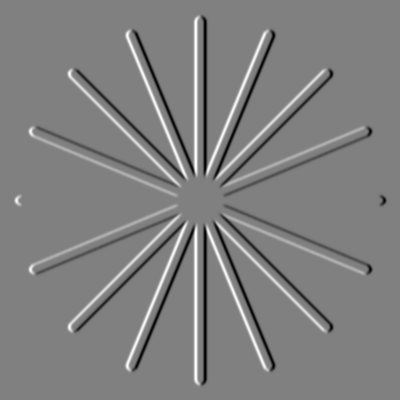

37348 kantpiksler


In [5]:
@interact(ksize=[("1", 1), ("3", 3), ("5", 5), ("7", 7), ("Scharr", -1)],
          vis=["styrke", "Sobel x", "Sobel y", "retning som farge"],
          terskel=(0, 255))
def utforsk(ksize=3, vis="styrke", terskel=0):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=ksize)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=ksize)
    styrke8 = cv2.normalize(cv2.magnitude(gx, gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    svak = styrke8 < terskel

    if vis in ("Sobel x", "Sobel y"):
        g = gx if vis == "Sobel x" else gy
        ut = np.clip(128 + g * 127 / max(np.abs(g).max(), 1e-9), 0, 255).astype(np.uint8)   # 0 blir grått
        ut[svak] = 128
    elif vis == "retning som farge":
        hsv = np.zeros((*img.shape, 3), np.uint8)
        hsv[..., 0] = (cv2.phase(gx, gy, angleInDegrees=True) / 2).astype(np.uint8)
        hsv[..., 1] = 255
        hsv[..., 2] = styrke8
        ut = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
        ut[svak] = 0
    elif terskel > 0:
        ut = np.where(svak, 0, 255).astype(np.uint8)   # binært kantbilde
    else:
        ut = styrke8

    cv2.imshow(f"{vis}, ksize={ksize}", ut)
    print(f"{np.count_nonzero(~svak & (styrke8 > 0))} kantpiksler")

### Prøv selv

- Bytt `cv2.CV_64F` med `cv2.CV_8U` i Sobel x. Da blir alle negative tall 0, og bare den ene siden av hver strek blir funnet. Vil du ha et 8-bits bilde, bruk `cv2.convertScaleAbs(gx)`, som tar absoluttverdien først.
- Lag en stjerne med flere vinkler eller tynnere streker med `img, vinkler = lag_stjerne(antall=12, tykkelse=3)` i den første kodecellen, og kjør cellene under på nytt. Er strekene bare 1–2 piksler tykke, smelter de to kantene sammen.
- Prøv et vanlig bilde: `img = cv2.imread("eksempel.png", cv2.IMREAD_GRAYSCALE)`. Ekte bilder har støy, så det hjelper ofte å jevne ut først med `cv2.GaussianBlur(img, (5, 5), 0)`.
- Sammenlign med `cv2.Canny(img, 50, 150)`. Canny bruker Sobel inni seg, men gjør kantene 1 piksel tynne og fjerner de svake.